# Picking the configurations that matter

Quantum chemistry problems are enormous matrices that you cannot store, let alone diagonalize. The
standard escape is to keep a small slice of the matrix and throw the rest away. This notebook is about
the part everyone glosses over, which is how you decide what to keep.

By the end you will have implemented two different ways of choosing, run them against each other, and
reproduced the measurement that the main criticism of the quantum approach rests on.


About 25 minutes. Run the cells in order.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from itertools import combinations
from scipy.linalg import eigh

rng = np.random.default_rng(0)

## What a configuration is

Electrons live in orbitals, which you can think of as the available slots. A configuration is just a statement of which slots are filled: slot 1 yes, slot 2 no, slot 3 yes, and so on. Write that as a string of bits and you have the whole idea.

The catch is that a molecule is not in one configuration. Its true state is a weighted sum over all of them, and finding those weights is the calculation being performed. We build a matrix whose rows and columns are labelled
by configurations, find its lowest eigenvector, and the entries of that eigenvector are the weights.

The matrix is exact. It is also far too big: the number of configurations grows combinatorially with the number of orbitals, and realistic problems have more rows than there are atoms on Earth.

## A model small enough to cheat on

We need something with the same structure as a real molecule but small enough that we can compute the exact answer and check our shortcuts against it. The Hubbard model is the standard choice.

Picture six sites in a row. Electrons can hop to a neighbouring site, which lowers the energy and is why bonds exist at all. Two electrons on the same site cost energy `U`, because electrons repel. That competition between hopping and repulsion is the entire model, and it is a stripped down version of what
makes real electronic structure hard.

Electrons come in two spins, so a configuration is a pair of bit strings, one per spin. We will put
three of each on six sites.

In [2]:
L = 6          # sites
n_up = 3
n_down = 3
t = 1.0        # how easily an electron hops to the next site
U = 8.0        # what it costs to put two electrons on the same site


def occupations(n_sites, n_electrons):
    """Every way to place n_electrons on n_sites, as bit masks."""
    return [sum(1 << i for i in c) for c in combinations(range(n_sites), n_electrons)]


configs = [(u, d) for u in occupations(L, n_up) for d in occupations(L, n_down)]
index = {c: k for k, c in enumerate(configs)}

print(f"{len(configs)} configurations")
print("\nfirst few, written out as bits (up / down):")
for u, d in configs[:4]:
    print(f"  {u:0{L}b}  {d:0{L}b}")

400 configurations

first few, written out as bits (up / down):
  000111  000111
  000111  001011
  000111  010011
  000111  100011


Now the matrix. Two rules.

A configuration's own diagonal entry is `U` times however many sites hold both an up and a down electron.
Off the diagonal, two configurations are connected if you can turn one into the other by moving a single
electron to an adjacent empty site, and that entry is minus `t`.

Normally fermions make this fiddly, because swapping two electrons flips the sign of the wavefunction and
you have to track that bookkeeping. We dodge it here: on an open chain where electrons only hop to the
very next site, there is never another electron in between, so the sign is always positive.

In [3]:
def single_hops(mask, n_sites):
    """Every configuration reachable by moving one electron to an adjacent empty site."""
    moves = []
    for i in range(n_sites - 1):
        if (mask >> i & 1) != (mask >> (i + 1) & 1):
            moves.append(mask ^ (1 << i) ^ (1 << (i + 1)))
    return moves


N = len(configs)
H = np.zeros((N, N))

for k, (up, down) in enumerate(configs):
    H[k, k] = U * bin(up & down).count("1")
    for up2 in single_hops(up, L):
        H[index[(up2, down)], k] -= t
    for down2 in single_hops(down, L):
        H[index[(up, down2)], k] -= t

print("symmetric:", np.allclose(H, H.T))
print(f"matrix is {H.shape[0]} by {H.shape[1]}, {np.count_nonzero(H) / H.size:.1%} filled")

symmetric: True
matrix is 400 by 400, 1.7% filled


Mostly zeros, which is the usual situation. Four hundred rows is small enough to diagonalize outright,
so let us get the answer we are going to spend the rest of the notebook trying to approximate.

exact ground state energy: -1.768099


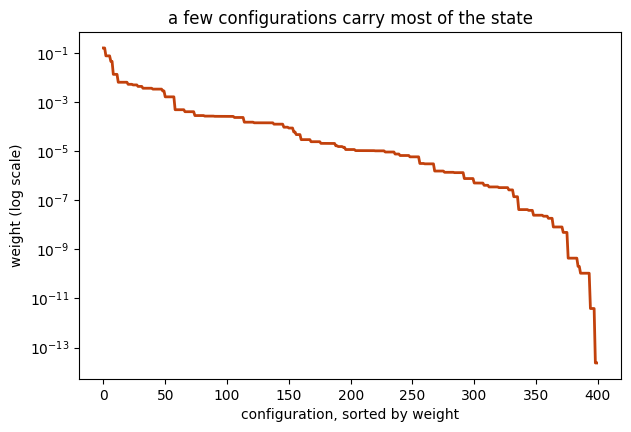

top   1 configurations hold  16.34% of the state
top  10 configurations hold  75.91% of the state
top  40 configurations hold  92.84% of the state
top 100 configurations hold  98.94% of the state
top 200 configurations hold  99.94% of the state


In [4]:
E_exact, C_exact = eigh(H)
ground = C_exact[:, 0]

print(f"exact ground state energy: {E_exact[0]:.6f}")

weights = ground**2
ranked = np.sort(weights)[::-1]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogy(ranked, color="#c2410c", lw=2)
ax.set_xlabel("configuration, sorted by weight")
ax.set_ylabel("weight (log scale)")
ax.set_title("a few configurations carry most of the state")
plt.show()

for k in [1, 10, 40, 100, 200]:
    print(f"top {k:3d} configurations hold {ranked[:k].sum() * 100:6.2f}% of the state")

That shape is the whole reason any of this is possible. The weights fall off over orders of magnitude,
so the overwhelming majority of the matrix contributes essentially nothing to the answer.

So keep the configurations with large weights, drop the rest, diagonalize the small matrix that is left.
Let us confirm that works.

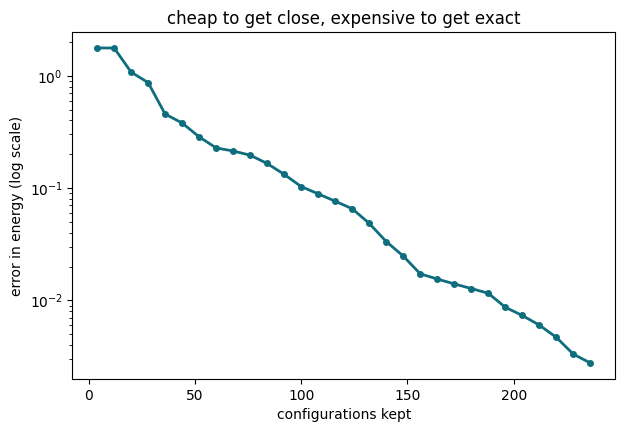

In [5]:
def energy_in_subspace(H, keep):
    """Lowest eigenvalue of H restricted to a subset of configurations."""
    keep = np.asarray(keep)
    return eigh(H[np.ix_(keep, keep)], eigvals_only=True)[0]


perfect_order = np.argsort(weights)[::-1]   # using the answer, which we will not be allowed to do

sizes = list(range(4, 240, 8))
perfect_errors = [abs(energy_in_subspace(H, perfect_order[:k]) - E_exact[0]) for k in sizes]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogy(sizes, perfect_errors, "o-", color="#0f6e7d", lw=2, ms=4)
ax.set_xlabel("configurations kept")
ax.set_ylabel("error in energy (log scale)")
ax.set_title("cheap to get close, expensive to get exact")
plt.show()

## The catch

Look at how we built `perfect_order`. We sorted by `weights`, which came from `C_exact`, which came from
diagonalizing the full matrix. We chose the important configurations by already knowing which ones were
important.

On a real problem that is circular. If you could diagonalize the full matrix you would not need to
truncate it.

So you need a rule that guesses which configurations will matter before you have the answer. Below are
the two rules this project is about.

## Rule one, perturbation theory

Start from a single configuration and grow outward. At each round, solve the small problem you have,
then ask of every configuration you have not kept: how strongly does this couple to what I have, and how
close in energy is it? Things that couple strongly and sit nearby matter most.

That ratio is a standard perturbation theory estimate. Keep the best scoring handful, repeat.

In [6]:
def perturbative_select(H, seed, n_keep, batch=8):
    """Grow a subspace by scoring outsiders with perturbation theory."""
    S = list(seed)
    diag = np.diag(H)

    while len(S) < n_keep:
        vals, vecs = eigh(H[np.ix_(S, S)])
        psi = np.zeros(len(H))
        psi[S] = vecs[:, 0]

        coupling = H @ psi
        gap = np.abs(vals[0] - diag)
        gap[gap < 1e-9] = 1e-9          # a configuration sitting exactly at the current energy would blow up

        score = coupling**2 / gap
        score[S] = -1.0

        S.extend(int(i) for i in np.argsort(score)[::-1][:batch])

    return np.array(S[:n_keep])


seed = [int(np.argmin(np.diag(H)))]     # the cheapest single configuration, the usual starting point
print("seed configuration:", configs[seed[0]])

seed configuration: (7, 56)


## Rule two, sampling

Here is the quantum version, and it is simpler than you might expect.

A quantum computer can prepare a state that approximates the one you are after. When you measure it, you
get back one configuration, chosen at random, with probability equal to its weight. Measure a few hundred
thousand times and the configurations that come back often are, by construction, the ones with large
weights.

So the machine does not solve anything. It acts as a biased random number generator over configurations,
and the classical computer does the actual diagonalization afterwards.

We are going to simulate that by drawing from the exact weights. Worth being clear that this is
generous to the quantum side: real hardware prepares an approximate state and adds noise on top, so its
samples are worse than what we are about to use. If sampling loses even under these conditions, that
tells you something.

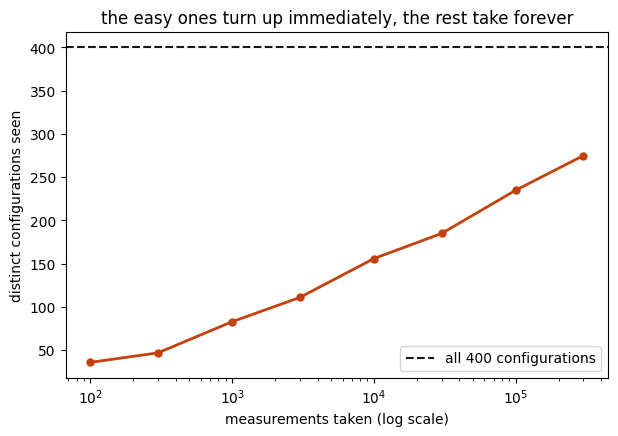

    100 shots  ->   36 distinct configurations
    300 shots  ->   47 distinct configurations
  1,000 shots  ->   83 distinct configurations
  3,000 shots  ->  111 distinct configurations
 10,000 shots  ->  156 distinct configurations
 30,000 shots  ->  185 distinct configurations
100,000 shots  ->  235 distinct configurations
300,000 shots  ->  275 distinct configurations


In [7]:
def sample_select(weights, n_shots, rng):
    """Draw configurations the way a quantum computer would, and report the unique ones."""
    draws = rng.choice(len(weights), size=n_shots, p=weights)
    found, counts = np.unique(draws, return_counts=True)
    return found, counts


shot_budgets = [100, 300, 1000, 3000, 10000, 30000, 100000, 300000]
discovered = [len(sample_select(weights, n, rng)[0]) for n in shot_budgets]

fig, ax = plt.subplots(figsize=(7, 4.5))
ax.semilogx(shot_budgets, discovered, "o-", color="#c2410c", lw=2, ms=5)
ax.axhline(N, color="#14181d", ls="--", lw=1.5, label=f"all {N} configurations")
ax.set_xlabel("measurements taken (log scale)")
ax.set_ylabel("distinct configurations seen")
ax.set_title("the easy ones turn up immediately, the rest take forever")
ax.legend()
plt.show()

for n, d in zip(shot_budgets, discovered):
    print(f"{n:>7,} shots  ->  {d:3d} distinct configurations")

That flattening curve is the heart of the published criticism of this whole approach.

The problem is that sampling keeps handing you configurations you already have. Early on every
measurement is informative. Later you are paying thousands of measurements for one new configuration,
and the ones you are still missing are exactly the rare ones, which is where the remaining accuracy
lives. It is the coupon collector problem wearing a lab coat.

Reinholdt and coauthors made this argument in 2025 and it is the main thing the quantum side has to
answer. If you want the original it is [arXiv:2501.07231](https://arxiv.org/abs/2501.07231).

## Running them against each other

Fair comparison means equal subspace size. Both methods get to keep exactly `k` configurations, and we
check which `k` gives the lower energy.

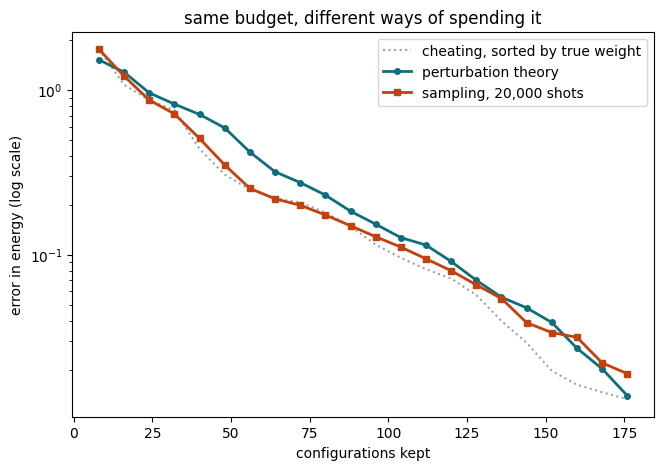

k=  8   perturbation 1.52546   sampling 1.76810
k= 40   perturbation 0.71129   sampling 0.50851
k= 72   perturbation 0.27460   sampling 0.20008
k=104   perturbation 0.12736   sampling 0.11151
k=136   perturbation 0.05538   sampling 0.05437
k=168   perturbation 0.02039   sampling 0.02214


In [8]:
budget = 20000
found, counts = sample_select(weights, budget, rng)
sampled_order = found[np.argsort(counts)[::-1]]    # most frequently measured first

sizes = list(range(8, min(len(sampled_order), 200), 8))

pert_errors, samp_errors, best_errors = [], [], []
for k in sizes:
    pert_errors.append(abs(energy_in_subspace(H, perturbative_select(H, seed, k)) - E_exact[0]))
    samp_errors.append(abs(energy_in_subspace(H, sampled_order[:k]) - E_exact[0]))
    best_errors.append(abs(energy_in_subspace(H, perfect_order[:k]) - E_exact[0]))

fig, ax = plt.subplots(figsize=(7.5, 5))
ax.semilogy(sizes, best_errors, color="#9aa1a8", lw=1.5, ls=":",
            label="cheating, sorted by true weight")
ax.semilogy(sizes, pert_errors, "o-", color="#0f6e7d", lw=2, ms=4, label="perturbation theory")
ax.semilogy(sizes, samp_errors, "s-", color="#c2410c", lw=2, ms=4, label=f"sampling, {budget:,} shots")
ax.set_xlabel("configurations kept")
ax.set_ylabel("error in energy (log scale)")
ax.set_title("same budget, different ways of spending it")
ax.legend()
plt.show()

for k, p, s in list(zip(sizes, pert_errors, samp_errors))[::4]:
    print(f"k={k:3d}   perturbation {p:.5f}   sampling {s:.5f}")

## What you are looking at

The dotted grey line is the best anyone could possibly do, since it sorts by the exact weights. Neither
real method can beat it.

Where the other two land relative to each other is the actual research question, and it is not settled.
Published comparisons for electrons currently favour the classical side, but the result depends on the
system, on how good a state the hardware can prepare, and on how many measurements you can afford.

Two things worth doing before you take any single run seriously. The sampling curve moves around between
random seeds, so run it a few times. And `budget` matters enormously, so try 2,000 and 200,000 and watch
the orange line shift.

## Things to poke at

- Turn `U` up to 20 or down to 2. Large `U` makes the state more lopsided, which should favour sampling,
  since the weights it needs to find are concentrated. Does it?
- Add noise to the sampled distribution before drawing from it, so it stops matching the exact answer.
  That is much closer to what real hardware gives you.
- Change `batch` in `perturbative_select`. Smaller batches mean more rounds and better choices, at the
  cost of more work. Where is the sweet spot?
- Go to `L = 8` with four electrons of each spin, which is 4,900 configurations. Everything should still
  run, just slower.

## Where this connects

Both rules here are doing the same job as the truncation in the vibrational notebook, just for electrons
instead of vibrations. The open question we would be working on is whether rule two beats rule one, and
for vibrations nobody has checked at all.